In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [22]:
# ==========================================
# STEP 1: LOAD THE DATA
# ==========================================
# Replace 'Online_Retail.csv' with the actual path of the file you download
try:
    df = pd.read_csv(r"C:\Users\ashut\Downloads\archive\online_retail.csv", encoding='ISO-8859-1')
    print("Data loaded successfully! Shape:", df.shape)
except FileNotFoundError:
    print("Error: Please check the file path.")

# Display the first few rows to check column names
    print(df.head())

Data loaded successfully! Shape: (541909, 8)


In [23]:
# ==========================================
# STEP 2: DATA CLEANING (PANDAS)
# ==========================================
print("\n--- Starting Data Cleaning ---")

# 1. Drop rows where CustomerID is missing (crucial for customer analysis)
df.dropna(subset=['CustomerID'], inplace=True)

# 2. Convert CustomerID to integer (stops it from looking like a decimal float)
df['CustomerID'] = df['CustomerID'].astype(int)

# 3. Clean up the Date column into standard Datetime format
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

# 4. Feature Engineering: Create Total Revenue column
df['Total_Revenue'] = df['Quantity'] * df['UnitPrice']

# 5. Filter out anomalies (Negative quantities/prices indicate returns or errors)
df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)]

# 6. Extract Month and Year for trend analysis
df['YearMonth'] = df['InvoiceDate'].dt.to_period('M')
df['DayOfWeek'] = df['InvoiceDate'].dt.day_name()

print("Cleaning complete! New Shape:", df.shape)


--- Starting Data Cleaning ---
Cleaning complete! New Shape: (397884, 11)


In [24]:
# ==========================================
# STEP 3: DATA ANALYSIS & INSIGHTS
# ==========================================
print("\n--- Generating Business Metrics ---")

total_rev = df['Total_Revenue'].sum()
total_orders = df['InvoiceNo'].nunique()
avg_order_value = total_rev / total_orders

print(f"Total Revenue Generated: ₹{total_rev:,.2f}")
print(f"Total Unique Orders: {total_orders}")
print(f"Average Order Value (AOV): ₹{avg_order_value:,.2f}")


--- Generating Business Metrics ---
Total Revenue Generated: ₹8,911,407.90
Total Unique Orders: 18532
Average Order Value (AOV): ₹480.87


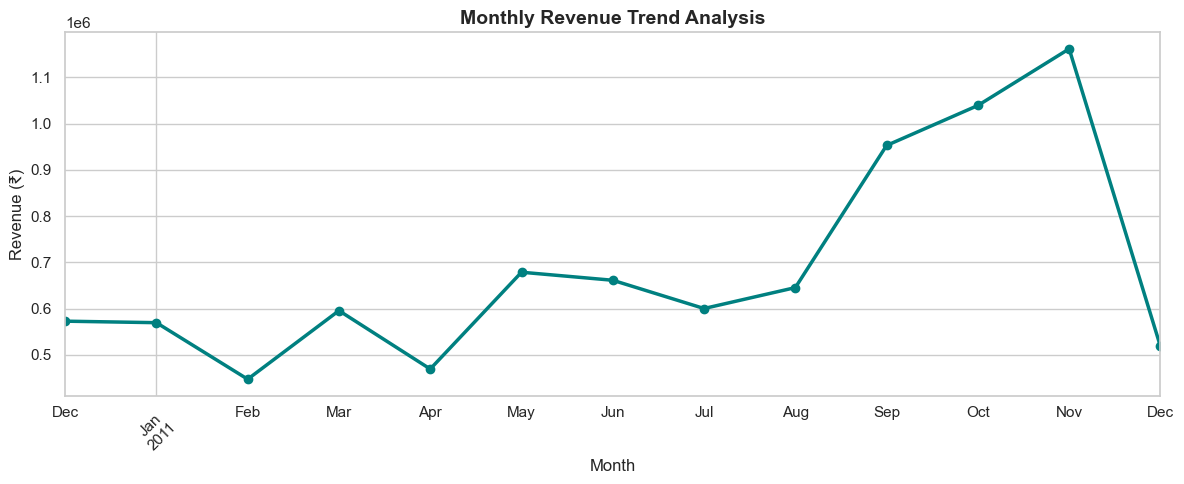

In [25]:
# ==========================================
# STEP 4: VISUALIZATIONS (MATPLOTLIB)
# ==========================================
# Set styling for cleaner graphs
sns.set_theme(style="whitegrid")

# Chart 1: Monthly Revenue Trend
plt.figure(figsize=(12, 5))
monthly_sales = df.groupby('YearMonth')['Total_Revenue'].sum()
monthly_sales.plot(kind='line', marker='o', color='teal', linewidth=2.5)
plt.title('Monthly Revenue Trend Analysis', fontsize=14, fontweight='bold')
plt.xlabel('Month', fontsize=12)
plt.ylabel('Revenue (₹)', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('monthly_revenue_trend.png', dpi=300)
plt.show()

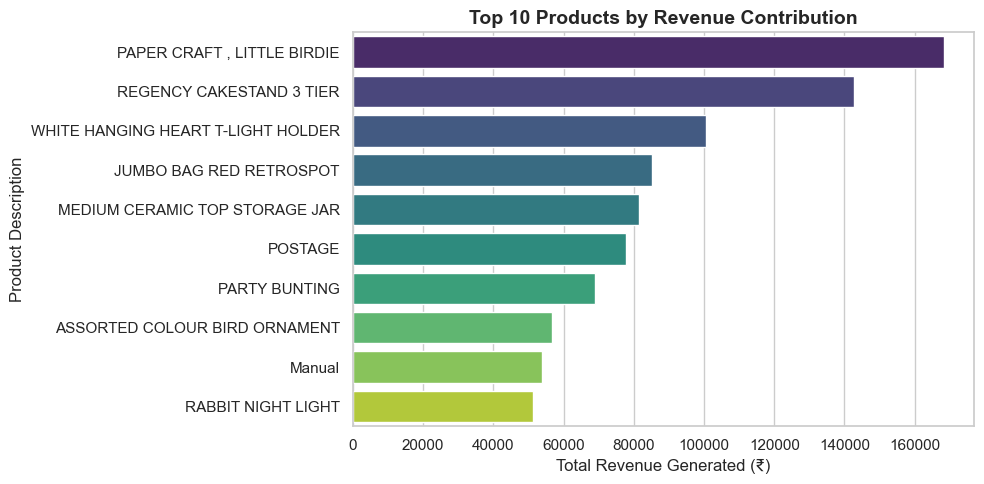

In [26]:
# Chart 2: Top 10 Best Selling Products by Revenue
plt.figure(figsize=(10, 5))
top_products = df.groupby('Description')['Total_Revenue'].sum().nlargest(10)
sns.barplot(x=top_products.values, y=top_products.index, palette='viridis', hue=top_products.index, legend=False)
plt.title('Top 10 Products by Revenue Contribution', fontsize=14, fontweight='bold')
plt.xlabel('Total Revenue Generated (₹)', fontsize=12)
plt.ylabel('Product Description', fontsize=12)
plt.tight_layout()
plt.savefig('top_10_products.png', dpi=300)
plt.show()

In [28]:
# ==========================================
# STEP 5: EXPORT CLEAN DATA FOR POWER BI
# ==========================================
# Save this cleaned data to feed directly into your Power BI Dashboard
df.to_csv(
    r"C:\Users\ashut\Downloads\Cleaned_Online_Retail.csv", index=False
)
print("\nCleaned data exported as 'Cleaned_Online_Retail.csv' for Power BI.")


Cleaned data exported as 'Cleaned_Online_Retail.csv' for Power BI.
